In [3]:
import sqlite3
import pandas as pd 

In [4]:
conn=sqlite3.connect("RetailIQ 360.db")
cursor=conn.cursor()
    

# Null valuels, Duplicate values, Outliers values are being tackled now!

# For dim_customer

In [7]:
dim_customer = pd.read_sql(
    "SELECT * FROM dim_customer",
    conn
)

In [16]:
dim_customer.isnull().sum()

customer_id    0
first_name     0
last_name      8
segment        0
city           0
state          0
country        0
zipcode        3
dtype: int64

In [19]:
dim_customer['zipcode']=dim_customer['zipcode'].fillna(0)


In [20]:
dim_customer.isnull().sum()

customer_id    0
first_name     0
last_name      8
segment        0
city           0
state          0
country        0
zipcode        0
dtype: int64

In [21]:
dim_customer.duplicated().sum()

np.int64(0)

In [ ]:
Q1 = fact_df['sales'].quantile(0.25)
Q3 = fact_df['sales'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# For dim_product

In [22]:
dim_product = pd.read_sql(
    "SELECT * FROM dim_product",
    conn
)

In [27]:
dim_product.isnull().sum()

product_id         0
product_name       0
category_name      0
department_name    0
product_price      0
dtype: int64

In [28]:
dim_product.duplicated().sum()

np.int64(0)

# For dim_shipping

In [23]:
dim_shipping = pd.read_sql(
    "SELECT * FROM dim_shipping",
    conn
)

In [29]:
dim_shipping.isnull().sum()

shipping_id                      0
Shipping Mode                    0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64

In [30]:
dim_shipping.duplicated().sum()

np.int64(0)

# For dim_location

In [24]:
dim_location = pd.read_sql(
    "SELECT * FROM dim_location",
    conn
)

In [31]:
dim_location.isnull().sum()

Order City       0
Order State      0
Order Country    0
Order Region     0
Latitude         0
Longitude        0
location_id      0
dtype: int64

In [32]:
dim_location.duplicated().sum()

np.int64(0)

# For dim_date

In [25]:
dim_date = pd.read_sql(
    "SELECT * FROM dim_date",
    conn
)

In [33]:
dim_date.isnull().sum()

full_date     0
year          0
month         0
month_name    0
quarter       0
day           0
weekday       0
is_weekend    0
dtype: int64

In [34]:
dim_date.duplicated().sum()

np.int64(0)

# For fact_order_items

In [26]:
fact_order_items = pd.read_sql(
    "SELECT * FROM fact_order_items",
    conn
)

In [35]:
fact_order_items.isnull().sum()

order_id        0
customer_id     0
product_id      0
sales           0
quantity        0
discount        0
profit          0
item_total      0
profit_ratio    0
order_date      0
dtype: int64

In [36]:
fact_order_items.duplicated().sum()

np.int64(0)

# First tackle profit column outliers!

In [40]:
# Profit Outlier Analysis

Q1 = fact_order_items['profit'].quantile(0.25)
Q3 = fact_order_items['profit'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

profit_outliers = fact_order_items[
    (fact_df['profit'] < lower) |
    (fact_df['profit'] > upper)
]

print("Outlier Count:", len(profit_outliers))

profit_outliers.head(20)

Outlier Count: 1610


C:\Users\User\AppData\Local\Temp\ipykernel_22552\3929525350.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  profit_outliers = fact_order_items[


,order_id,customer_id,product_id,sales,quantity,discount,profit,item_total,profit_ratio,order_date
40,75900,19453,1360,327.750000,1,29.500000,143.160004,298.250000,0.48,2018-01-12 22:48:00
130,55876,5421,365,299.950012,5,0.000000,140.979996,299.950012,0.47,2017-03-26 15:30:00
369,75885,19438,1360,327.750000,1,16.389999,-71.300003,311.359985,-0.23,2018-01-12 17:32:00
395,75859,19412,1360,327.750000,1,52.439999,-61.939999,275.309998,-0.23,2018-01-12 08:26:00
443,75811,19364,1360,327.750000,1,22.940001,-72.540001,304.809998,-0.24,2018-01-11 15:37:00
481,13890,9120,191,399.959992,4,4.000000,138.589996,395.959992,0.35,2015-07-22 17:56:00
483,11321,9415,191,399.959992,4,8.000000,141.110001,391.959992,0.36,2015-06-15 05:54:00
533,16444,9011,365,299.950012,5,53.990002,-67.639999,245.960007,-0.28,2015-08-29 00:42:00
542,11936,724,565,350.000000,5,59.500000,-72.629997,290.500000,-0.25,2015-06-24 05:21:00
789,19496,7521,191,399.959992,4,51.990002,-69.589996,347.970001,-0.20,2015-10-12 13:58:00


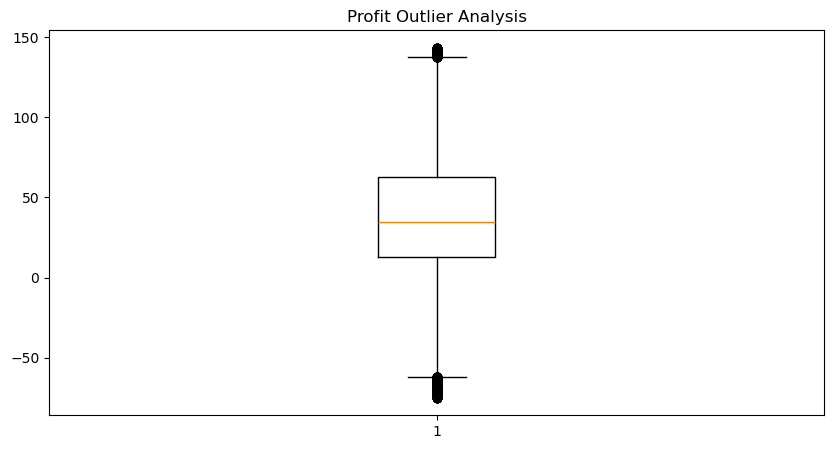

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.boxplot(fact_order_items['profit'])

plt.title("Profit Outlier Analysis")

plt.show()

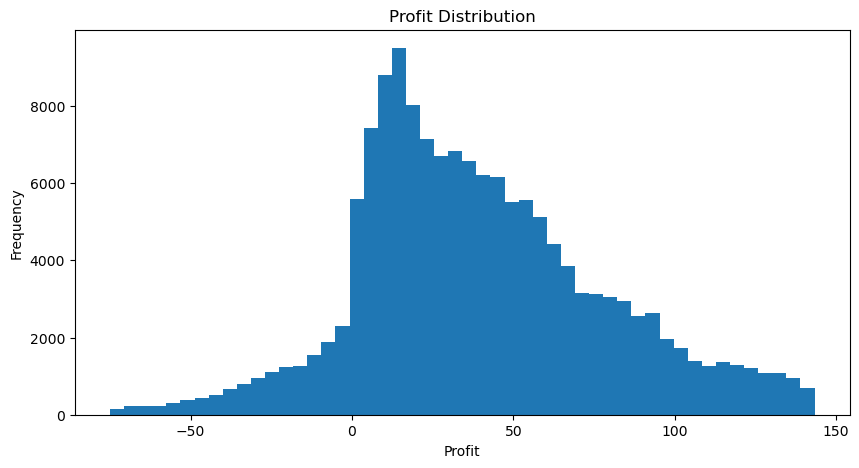

In [42]:
plt.figure(figsize=(10,5))

plt.hist(fact_order_items['profit'], bins=50)

plt.title("Profit Distribution")

plt.xlabel("Profit")

plt.ylabel("Frequency")

plt.show()

In [47]:
# ==========================================
# PROFIT OUTLIER HANDLING
# PROFESSIONAL ANALYTICAL APPROACH
# ==========================================

import numpy as np

# ------------------------------------------
# STEP 1 — CALCULATE IQR
# ------------------------------------------

Q1 = fact_order_items['profit'].quantile(0.25)
Q3 = fact_order_items['profit'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# ------------------------------------------
# STEP 2 — CREATE OUTLIER FLAG
# ------------------------------------------

fact_order_items['profit_outlier'] = np.where(
    (fact_order_items['profit'] < lower_bound) |
    (fact_order_items['profit'] > upper_bound),
    1,
    0
)

# ------------------------------------------
# STEP 3 — CHECK OUTLIER COUNT
# ------------------------------------------

outlier_count = fact_order_items['profit_outlier'].sum()

print("\nProfit Outlier Count:", outlier_count)

# ------------------------------------------
# STEP 4 — PREVIEW OUTLIER ROWS
# ------------------------------------------

profit_outliers = fact_order_items[
    fact_order_items['profit_outlier'] == 1
]

print("\nSample Profit Outliers:")

display(
    profit_outliers.head()
)

# ------------------------------------------
# STEP 5 — OPTIONAL CAPPING
# ------------------------------------------
# We will cap only extreme statistical influence
# while keeping rows inside dataset

upper_cap = fact_order_items['profit'].quantile(0.99)
lower_cap = fact_order_items['profit'].quantile(0.01)

fact_order_items['profit_capped'] = fact_order_items['profit'].clip(
    lower=lower_cap,
    upper=upper_cap
)

print("\nLower Cap:", lower_cap)
print("Upper Cap:", upper_cap)

# ------------------------------------------
# STEP 6 — COMPARE ORIGINAL VS CAPPED
# ------------------------------------------

comparison_df = fact_order_items[
    ['profit', 'profit_capped', 'profit_outlier']
]

print("\nComparison Preview:")

display(
    comparison_df.sample(40)
)

# ------------------------------------------
# STEP 7 — FINAL VALIDATION
# ------------------------------------------

print("\nFinal Fact Table Shape:")
print(fact_order_items.shape)

print("\nNew Columns Added:")
print([
    'profit_outlier',
    'profit_capped'
])

Q1: 12.82999992
Q3: 62.61000061
IQR: 49.78000069
Lower Bound: -61.840001115
Upper Bound: 137.280001645

Profit Outlier Count: 1610

Sample Profit Outliers:


,order_id,customer_id,product_id,sales,quantity,discount,profit,item_total,profit_ratio,order_date,profit_outlier,profit_capped
40,75900,19453,1360,327.750000,1,29.500000,143.160004,298.250000,0.48,2018-01-12 22:48:00,1,135.350006
130,55876,5421,365,299.950012,5,0.000000,140.979996,299.950012,0.47,2017-03-26 15:30:00,1,135.350006
369,75885,19438,1360,327.750000,1,16.389999,-71.300003,311.359985,-0.23,2018-01-12 17:32:00,1,-49.000000
395,75859,19412,1360,327.750000,1,52.439999,-61.939999,275.309998,-0.23,2018-01-12 08:26:00,1,-49.000000
443,75811,19364,1360,327.750000,1,22.940001,-72.540001,304.809998,-0.24,2018-01-11 15:37:00,1,-49.000000



Lower Cap: -49.0
Upper Cap: 135.3500061

Comparison Preview:


,profit,profit_capped,profit_outlier
120070,29.740000,29.740000,0
104423,77.440002,77.440002,0
146470,111.989998,111.989998,0
15598,67.430000,67.430000,0
160234,31.670000,31.670000,0
90598,26.299999,26.299999,0
18036,111.370003,111.370003,0
121516,10.040000,10.040000,0
23796,48.020000,48.020000,0
82107,22.080000,22.080000,0



Final Fact Table Shape:
(149181, 12)

New Columns Added:
['profit_outlier', 'profit_capped']


In [64]:

fact_order_items.head(5)


,order_id,customer_id,product_id,sales,quantity,discount,profit,item_total,profit_ratio,order_date,profit_outlier,profit_capped,profit_margin_pct,avg_selling_price
0,77202,20755,1360,327.75,1,13.110000,91.250000,314.640015,0.29,2018-01-31 22:56:00,0,91.250000,27.841342,327.75
3,75937,19490,1360,327.75,1,22.940001,22.860001,304.809998,0.08,2018-01-13 11:45:00,0,22.860001,6.974829,327.75
4,75936,19489,1360,327.75,1,29.500000,134.210007,298.250000,0.45,2018-01-13 11:24:00,0,134.210007,40.948896,327.75
5,75935,19488,1360,327.75,1,32.779999,18.580000,294.980011,0.06,2018-01-13 11:03:00,0,18.580000,5.668955,327.75
6,75934,19487,1360,327.75,1,39.330002,95.180000,288.420013,0.33,2018-01-13 10:42:00,0,95.180000,29.040427,327.75


# for item_total

In [52]:
# Profit Outlier Analysis

Q1 = fact_order_items['item_total'].quantile(0.25)
Q3 = fact_order_items['item_total'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

item_total_outlier = fact_order_items[
    (fact_order_items['item_total'] < lower) |
    (fact_order_items['item_total'] > upper)
]

print("Outlier Count:", len(item_total_outlier))

item_total_outlier.head(40)

Outlier Count: 1050


,order_id,customer_id,product_id,sales,quantity,discount,profit,item_total,profit_ratio,order_date,profit_outlier,profit_capped
150,69610,13163,1349,452.040008,1,18.080000,135.830002,433.959992,0.31,2017-10-13 03:08:00,0,135.350006
153,69626,13179,1349,452.040008,1,24.860001,21.360001,427.179993,0.05,2017-10-13 08:44:00,0,21.360001
156,69643,13196,1349,452.040008,1,31.639999,126.120003,420.399994,0.30,2017-10-13 14:41:00,0,126.120003
243,74796,18349,1353,461.480011,1,25.379999,43.610001,436.100006,0.10,2017-12-27 20:01:00,0,43.610001
265,74723,18276,1353,461.480011,1,32.299999,37.770000,429.179993,0.09,2017-12-26 18:26:00,0,37.770000
529,15766,6416,191,499.950012,5,59.990002,114.389999,439.959992,0.26,2015-08-19 03:10:00,0,114.389999
913,65249,2269,191,499.950012,5,59.990002,118.790001,439.959992,0.27,2017-08-10 11:16:00,0,118.790001
914,17449,10708,191,499.950012,5,64.989998,49.150002,434.959992,0.11,2015-09-12 16:48:00,0,49.150002
1365,69683,13236,1349,452.040008,1,13.560000,131.539993,438.480011,0.30,2017-10-14 04:42:00,0,131.539993
1368,69478,13031,1349,452.040008,1,54.240002,-69.610001,397.799988,-0.18,2017-10-11 04:53:00,1,-49.000000


# for discount  

In [62]:
# Profit Outlier Analysis

Q1 = fact_order_items['discount'].quantile(0.25)
Q3 = fact_order_items['discount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

discount_outlier = fact_order_items[
    (fact_order_items['discount'] < lower) |
    (fact_order_items['discount'] > upper)
]

print("Outlier Count:", len(discount_outlier))

item_total_outlier.head(5)

Outlier Count: 3662


,order_id,customer_id,product_id,sales,quantity,discount,profit,item_total,profit_ratio,order_date,profit_outlier,profit_capped
150,69610,13163,1349,452.040008,1,18.080000,135.830002,433.959992,0.31,2017-10-13 03:08:00,0,135.350006
153,69626,13179,1349,452.040008,1,24.860001,21.360001,427.179993,0.05,2017-10-13 08:44:00,0,21.360001
156,69643,13196,1349,452.040008,1,31.639999,126.120003,420.399994,0.30,2017-10-13 14:41:00,0,126.120003
243,74796,18349,1353,461.480011,1,25.379999,43.610001,436.100006,0.10,2017-12-27 20:01:00,0,43.610001
265,74723,18276,1353,461.480011,1,32.299999,37.770000,429.179993,0.09,2017-12-26 18:26:00,0,37.770000


# feature engineering start from here

# building engineered features for fact_order_items

In [54]:
fact_order_items['profit_margin_pct'] = (
    fact_order_items['profit'] /
    fact_order_items['sales']
) * 100

In [56]:
fact_order_items['avg_selling_price'] = (
    fact_order_items['sales'] /
    fact_order_items['quantity']
)

In [70]:
fact_order_items['dicount_pct'] =(
    fact_order_items['discount']/
    fact_order_items['sales']
)* 100

In [80]:
fact_order_items['order_date'] = pd.to_datetime(
    fact_order_items['order_date']
)

fact_order_items['order_month'] = (
    fact_order_items['order_date'].dt.month
)

In [81]:
fact_order_items['quarter'] = (
    fact_order_items['order_date'].dt.quarter
)

In [82]:
fact_order_items['weekday'] = (
    fact_order_items['order_date'].dt.day_name()
)

In [83]:
fact_order_items['is_weekend'] = (
    fact_order_items['weekday']
    .isin(['Saturday', 'Sunday'])
)

In [78]:
customer_spend = (
    fact_order_items
    .groupby('customer_id')['sales']
    .sum()
    .reset_index()
)

In [85]:
customer_orders = (
    fact_order_items
    .groupby('customer_id')['order_id']
    .nunique()
    .reset_index()
)

In [86]:
    fact_order_items.to_sql(
    'fact_order_items',
    conn,
    if_exists='replace',
    index=False
)

149181

In [89]:
customer_spend.to_sql(
    'customer_total_spend',
    conn,
    if_exists='replace',
    index=False
)

17994

In [90]:
customer_orders.to_sql(
    'customer_total_orders',
    conn,
    if_exists='replace',
    index=False
)

17994

# building feature engineered columns for dim_shipping table:

In [58]:
dim_shipping=pd.read_sql('select * from dim_shipping',conn)

In [63]:
dim_shipping.head(5)

,shipping_id,Shipping Mode,Delivery Status,Late_delivery_risk,Days for shipping (real),Days for shipment (scheduled),delievery_delay
0,1,Standard Class,Advance shipping,0,3,4,-1
1,2,Standard Class,Late delivery,1,5,4,1
2,3,Standard Class,Shipping on time,0,4,4,0
3,4,Standard Class,Advance shipping,0,2,4,-2
4,5,Standard Class,Shipping canceled,0,6,4,2


In [61]:
dim_shipping['delievery_delay']=dim_shipping['Days for shipping (real)']-dim_shipping['Days for shipment (scheduled)']

In [88]:
dim_shipping.to_sql(
    'dim_shipping',
    conn,
    if_exists='replace',
    index=False
)

26